# 01 — Écrire un réseau à la main, puis lire un réseau entraîné par RL

**Références · Weight-Space Programming** · durée conseillée : ~15 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/references/01_weight_space_programming/01_write_and_read_a_policy.ipynb)

Dans le billet, Astra **écrit** des réseaux qui jouent à des jeux à partir de poids tous nuls (expérience 5), **lit** une politique entraînée pour dire à quel jeu elle joue (expérience 1), et **répare** une politique défaillante en modifiant ses poids (expérience 4). Nous faisons les trois sur un jeu assez petit pour tenir dans votre tête.

**À la fin de ce notebook, vous saurez :**
1. Écrire **à la main** les poids d'un réseau de politique qui fonctionne, sans entraînement.
2. Entraîner le même type de réseau par apprentissage par renforcement et **lire** sa première couche comme des images.
3. Montrer que le réseau entraîné a trouvé **le même algorithme** que celui écrit à la main.
4. **Réparer** un réseau cassé en modifiant ses poids, sans le réentraîner.

**Plan :**
1. Le jeu : *Catch*
2. Écrire à la main une politique à 2 neurones
3. Entraîner une politique 200→32→32→3 avec REINFORCE
4. Lire les poids entraînés
5. Réparer un réseau cassé en modifiant ses poids
6. Bilan, questions, exercices

In [1]:
# Sur Google Colab : récupérer le dépôt du cours (wsp.py est à côté de ce notebook).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("wsp.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/references/01_weight_space_programming

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import wsp  # fichier wsp.py, à côté de ce notebook
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cu132


## 1. Le jeu : *Catch*

Une balle apparaît dans une colonne aléatoire de la ligne du haut d'une grille 10×10 et descend d'une ligne à chaque pas. Une raquette d'une case est posée sur la ligne du bas. À chaque pas, la politique choisit **gauche, rester ou droite**. Après 9 pas, la balle atteint la ligne du bas : elle est attrapée si elle se trouve dans la colonne de la raquette.

L'observation a le même format que MinAtar (expérience 5) : une grille 10×10 **par type d'objet** (canal 0 = balle, canal 1 = raquette), aplatie en **200 nombres**, tous à 0 sauf deux 1.

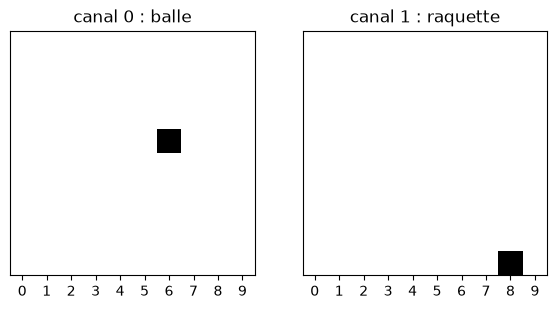

colonne de la balle : 6 | colonne de la raquette : 8
observation = 200 nombres, dont 2 valent 1


In [3]:
g = torch.Generator().manual_seed(3)
s = wsp.reset(1, g)
for _ in range(4):
    wsp.step(s, torch.tensor([1]))   # rester sur place, laisser la balle descendre un peu
obs = wsp.observe(s).view(2, wsp.W, wsp.W)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, ch, name in zip(axes, obs, ["canal 0 : balle", "canal 1 : raquette"]):
    ax.imshow(ch, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(name); ax.set_xticks(range(10)); ax.set_yticks([])
plt.tight_layout(); plt.show()
print("colonne de la balle :", s["bx"].item(), "| colonne de la raquette :", s["px"].item())
print("observation = 200 nombres, dont", int(wsp.observe(s).sum()), "valent 1")

In [4]:
random_policy = lambda o: torch.zeros(o.shape[0], 3)      # logits égaux = actions uniformément aléatoires
print(f"la politique aléatoire attrape {wsp.play(random_policy, greedy=False):.1%} des balles")

la politique aléatoire attrape 9.8% des balles

## 2. Écrire la politique à la main

Avant d'entraîner quoi que ce soit, pensez comme un programmeur. Que doit calculer la politique ? Seulement le **signe** de

$$d = \text{colonne de la balle} - \text{colonne de la raquette}.$$

Si $d>0$, aller à droite. Si $d<0$, aller à gauche. Si $d=0$, rester.

**Étape 1 : obtenir les colonnes sous forme de nombres.** L'entrée est en one-hot. Si chaque case balle de la colonne $c$ a le poids $c$, le produit scalaire de ces poids avec l'entrée *est* la colonne de la balle. Même astuce pour la raquette.

**Étape 2 : découper le signe en deux neurones ReLU.**

$$h_0 = \text{ReLU}(b_x - p_x) \quad(\text{« la balle est à droite »}),\qquad h_1 = \text{ReLU}(p_x - b_x)\quad(\text{« la balle est à gauche »})$$

**Étape 3 : les transformer en logits d'action.** `droite = 10·h0`, `gauche = 10·h1`, `rester = 5` (un biais constant). Quand $d=0$, les deux neurones valent 0 et *rester* l'emporte. Quand $|d|\ge 1$, le côté correspondant reçoit au moins 10 > 5.

C'est un réseau **200 → 2 → 3** dont chaque poids est choisi exprès. Le voici, en partant de poids tous nuls comme dans l'expérience 5 :

In [5]:
net = nn.Sequential(nn.Linear(2 * wsp.W * wsp.W, 2), nn.ReLU(), nn.Linear(2, 3))
with torch.no_grad():
    for p in net.parameters():
        p.zero_()                                      # partir de rien
    col = torch.arange(wsp.W).float()                  # 0, 1, ..., 9
    ball = col.repeat(wsp.W)                           # la case balle (ligne r, colonne c) reçoit le poids c
    paddle = torch.zeros(wsp.W, wsp.W); paddle[-1] = col
    paddle = paddle.view(-1)                           # la case raquette (ligne du bas, colonne c) reçoit le poids c
    net[0].weight[0] = torch.cat([ball, -paddle])      # h0 = relu(bx - px)
    net[0].weight[1] = torch.cat([-ball, paddle])      # h1 = relu(px - bx)
    net[2].weight[:] = torch.tensor([[0., 10.],        # gauche = 10*h1
                                     [0.,  0.],        # rester = 5 (biais)
                                     [10., 0.]])       # droite = 10*h0
    net[2].bias[:] = torch.tensor([0., 5., 0.])

print(f"la politique écrite à la main attrape {wsp.play(net):.1%} des balles")
print("poids non nuls :", sum(int((p != 0).sum()) for p in net.parameters()), "sur",
      sum(p.numel() for p in net.parameters()))

la politique écrite à la main attrape 100.0% des balles
poids non nuls : 201 sur 411


**100 %, sans aucun entraînement.** C'est le weight-space programming en miniature : nous avons écrit le programme directement dans les poids.

*Regardons* la première couche. Chaque ligne de `net[0].weight` contient 200 nombres. Remise à la forme `(2, 10, 10)`, elle montre ce que le neurone « regarde » dans chaque canal. Gardez cette image en tête : nous allons la comparer à un réseau entraîné.

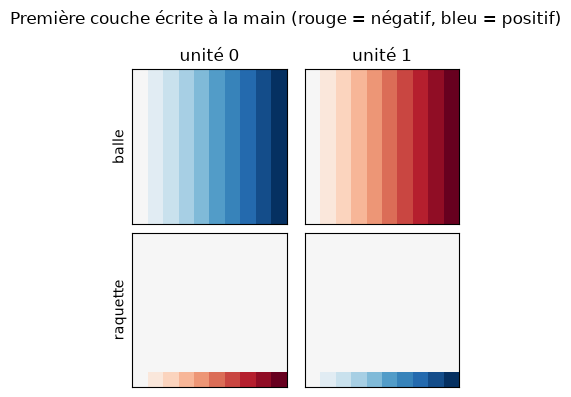

In [6]:
def show_rows(weight, units, title):
    w = weight.detach().view(-1, 2, wsp.W, wsp.W)
    fig, axes = plt.subplots(2, len(units), figsize=(1.9 * len(units), 4), squeeze=False)
    for k, u in enumerate(units):
        lim = w[u].abs().max().item()
        for ch in range(2):
            ax = axes[ch, k]
            ax.imshow(w[u, ch], cmap="RdBu", vmin=-lim, vmax=lim)
            ax.set_xticks([]); ax.set_yticks([])
            if k == 0: ax.set_ylabel(["balle", "raquette"][ch])
        axes[0, k].set_title(f"unité {u}")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_rows(net[0].weight, [0, 1], "Première couche écrite à la main (rouge = négatif, bleu = positif)")

Lisez-la comme le ferait Astra : les poids « balle » du neurone 0 croissent de gauche à droite (bleu à droite), et ses poids « raquette » font l'inverse, mais **uniquement sur la ligne du bas**. C'est « la balle est à droite de la raquette », en image.

## 3. Entraîner une politique par apprentissage par renforcement

Laissons maintenant la descente de gradient écrire les poids. Même entrée, un réseau plus grand (200 → 32 → 32 → 3, tanh, comme dans l'expérience 1), entraîné avec **REINFORCE**, la méthode de *policy gradient* la plus simple. (Le billet utilise PPO, une variante plus stable.)

La règle tient en une ligne : pour chaque épisode, on augmente la log-probabilité des actions choisies, proportionnellement à l'écart entre le résultat de l'épisode et la moyenne (+1 si la balle est attrapée, −1 si elle est ratée).

la politique entraînée attrape 97.9% des balles


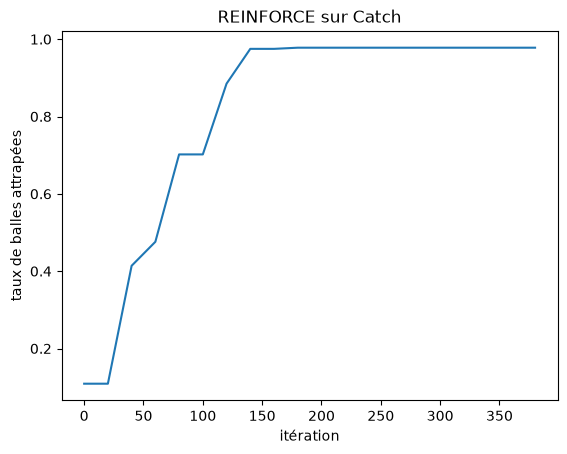

In [7]:
torch.manual_seed(0)
policy = nn.Sequential(nn.Linear(200, 32), nn.Tanh(),
                       nn.Linear(32, 32), nn.Tanh(),
                       nn.Linear(32, 3))
opt = torch.optim.Adam(policy.parameters(), lr=3e-3)
init_first_layer = policy[0].weight.detach().clone()   # gardée pour comparer plus tard

history = []
for it in range(400):
    s = wsp.reset(256)
    logps = []
    for _ in range(wsp.W - 1):
        dist = torch.distributions.Categorical(logits=policy(wsp.observe(s)))
        a = dist.sample()
        logps.append(dist.log_prob(a))
        wsp.step(s, a)
    reward = (s["px"] == s["bx"]).float() * 2 - 1          # +1 attrapée, -1 ratée
    advantage = reward - reward.mean()
    loss = -(torch.stack(logps).sum(0) * advantage).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 20 == 0:
        history.append((it, wsp.play(policy, batch=1000)))

print(f"la politique entraînée attrape {wsp.play(policy):.1%} des balles")
plt.plot(*zip(*history)); plt.xlabel("itération"); plt.ylabel("taux de balles attrapées"); plt.title("REINFORCE sur Catch"); plt.show()

## 4. Lire les poids entraînés

Imaginez qu'on vous tende ces 7 523 nombres en vous demandant *« à quel jeu joue ce réseau ? »* (expérience 1). Commencez par la première couche, affichée exactement comme celle écrite à la main.

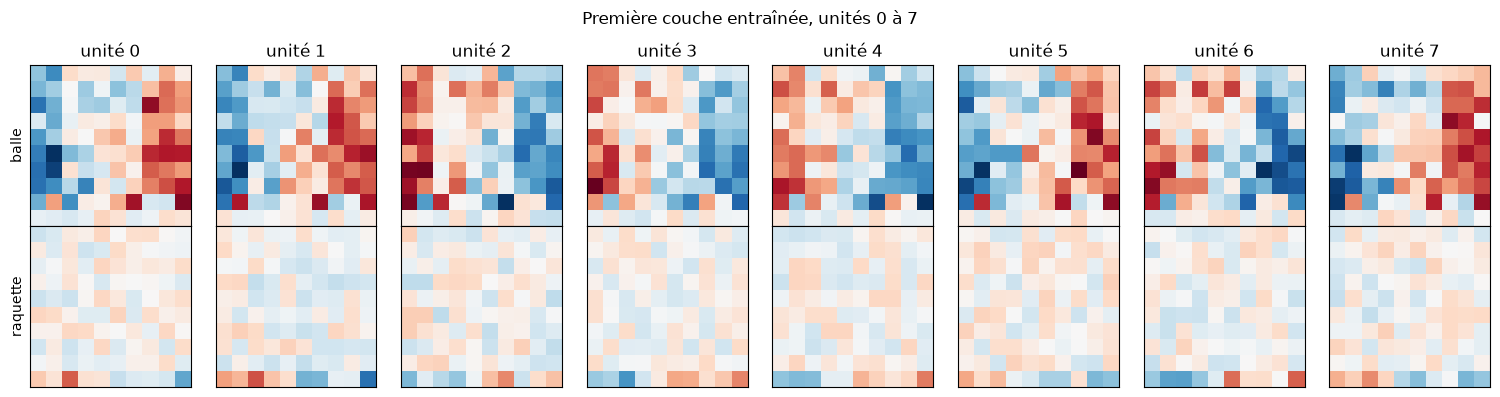

In [8]:
show_rows(policy[0].weight, range(8), "Première couche entraînée, unités 0 à 7")

Trois choses se voient sans exécuter le réseau :

1. **Canal balle : les bandes sont verticales.** Les poids changent d'une colonne à l'autre, mais presque pas d'une ligne à l'autre. Le réseau s'intéresse à *la colonne* de la balle, pas à sa hauteur.
2. **Canal raquette : seule la ligne du bas est structurée.** Les 90 autres poids « raquette » ressemblent à un faible bruit. Pourquoi ? La raquette n'est jamais ailleurs, donc ces entrées valent toujours 0 et **ne reçoivent jamais de gradient**. Elles gardent leurs valeurs initiales aléatoires. *Leçon pour lire des poids : des poids jamais touchés sont des restes de l'initialisation, pas du signal.* On peut le vérifier directement :
3. **Les deux canaux sont en miroir.** Là où les poids « balle » sont bleus, les poids « raquette » ont tendance à être rouges. C'est notre `bx − px`.

In [9]:
w = policy[0].weight.detach().view(32, 2, wsp.W, wsp.W)
w0 = init_first_layer.view(32, 2, wsp.W, wsp.W)
moved_unused = (w[:, 1, :-1] - w0[:, 1, :-1]).abs().max().item()
moved_bottom = (w[:, 1, -1] - w0[:, 1, -1]).abs().mean().item()
print(f"les poids raquette hors de la ligne du bas ont bougé d'au plus {moved_unused:.1e} pendant l'entraînement")
print(f"les poids raquette de la ligne du bas ont bougé de {moved_bottom:.3f} en moyenne")

les poids raquette hors de la ligne du bas ont bougé d'au plus 0.0e+00 pendant l'entraînement
les poids raquette de la ligne du bas ont bougé de 0.087 en moyenne


Le point 3 se mesure aussi. Pour chaque unité cachée, construisons son **profil balle** (les poids balle moyennés sur les lignes → 10 nombres, un par colonne) et son **profil raquette** (la ligne du bas → 10 nombres). Si l'unité calcule quelque chose comme `bx − px`, le profil balle doit ressembler à l'**opposé** du profil raquette.

corrélation(profil balle, -profil raquette) par unité :
[0.7  0.73 0.6  0.79 0.85 0.7  0.64 0.75 0.8  0.65 0.89 0.53 0.78 0.79
 0.8  0.68 0.79 0.7  0.74 0.83 0.77 0.86 0.82 0.74 0.83 0.58 0.66 0.49
 0.72 0.77 0.72 0.81]
31 unités sur 32 sont des comparateurs « balle contre raquette »


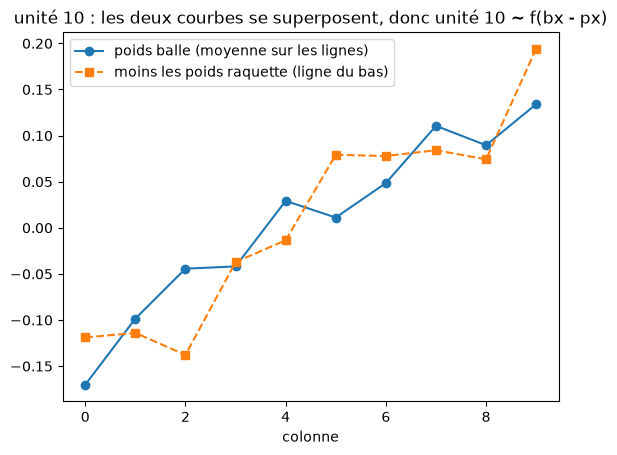

In [10]:
ball_profile = w[:, 0].mean(dim=1)        # (32, 10)
paddle_profile = w[:, 1, -1]              # (32, 10)
corr = torch.tensor([torch.corrcoef(torch.stack([ball_profile[i], -paddle_profile[i]]))[0, 1]
                     for i in range(32)])
print("corrélation(profil balle, -profil raquette) par unité :")
print(corr.numpy().round(2))
print(f"{int((corr > 0.5).sum())} unités sur 32 sont des comparateurs « balle contre raquette »")

i = int(corr.argmax())
plt.plot(ball_profile[i], "o-", label="poids balle (moyenne sur les lignes)")
plt.plot(-paddle_profile[i], "s--", label="moins les poids raquette (ligne du bas)")
plt.xlabel("colonne"); plt.title(f"unité {i} : les deux courbes se superposent, donc unité {i} ~ f(bx - px)"); plt.legend(); plt.show()

Presque chaque unité est un **comparateur entre la colonne de la balle et celle de la raquette** : le même algorithme que celui écrit à la main, réparti sur 32 unités bruitées au lieu de 2 unités nettes. L'optimiseur n'a pas trouvé de programme plus malin. Il a trouvé le nôtre, écrit de façon moins lisible.

C'est pour cela que lire des poids peut fonctionner : les réseaux entraînés implémentent souvent des algorithmes simples, et les poids le montrent dès qu'on sait ce que signifient les lignes et les colonnes de chaque matrice.

## 5. Réparer un réseau cassé en modifiant ses poids

L'expérience 4 donne à Astra une politique qui échoue et lui demande d'en réparer directement les poids. Voici notre version. Un bug matériel **met la caméra en miroir** : le réseau voit désormais la grille inversée de gauche à droite, mais ses actions agissent toujours sur le vrai monde.

In [11]:
def mirrored(net):
    "Le même réseau, mais il voit une observation inversée gauche-droite."
    return lambda o: net(o.view(-1, 2, wsp.W, wsp.W).flip(-1).reshape(-1, 200))

print(f"politique entraînée, caméra en miroir : {wsp.play(mirrored(policy)):.1%}")

politique entraînée, caméra en miroir : 0.0%


Elle s'éloigne maintenant de la balle à chaque fois. Un réentraînement la corrigerait, mais nous comprenons les poids : deux modifications différentes, d'une ligne chacune, suffiront.

**Correction A : recâbler l'entrée.** Chaque poids de la première couche est lié à une case de la grille. Si la caméra inverse les cases, inversons les poids de la même façon, et chaque produit scalaire retrouve son ancienne valeur.

**Correction B : recâbler la sortie.** Le réseau calcule désormais la décision pour le monde en miroir, donc son « gauche » signifie en réalité « droite ». Échangeons les lignes 0 et 2 de la couche de sortie.

In [12]:
import copy

fixed_a = copy.deepcopy(policy)
with torch.no_grad():
    w1 = fixed_a[0].weight.view(32, 2, wsp.W, wsp.W)
    fixed_a[0].weight.copy_(w1.flip(-1).reshape(32, 200))       # inverser les poids d'entrée gauche-droite

fixed_b = copy.deepcopy(policy)
with torch.no_grad():
    fixed_b[4].weight.copy_(fixed_b[4].weight[[2, 1, 0]])       # échanger les lignes « gauche » et « droite »
    fixed_b[4].bias.copy_(fixed_b[4].bias[[2, 1, 0]])

print(f"correction A (recâblage de l'entrée) : {wsp.play(mirrored(fixed_a)):.1%}")
print(f"correction B (recâblage de la sortie) : {wsp.play(mirrored(fixed_b)):.1%}")

correction A (recâblage de l'entrée) : 97.9%
correction B (recâblage de la sortie) : 97.9%


Les deux réparations fonctionnent, et aucune n'a demandé le moindre pas de gradient. La correction A réarrange les 6 400 poids de la première couche. La correction B déplace 64 poids et 2 biais. **Quand on sait ce que signifie une matrice, la modification est évidente.** C'est tout le pari du billet, appliqué à une échelle où l'on peut vérifier chaque étape.

---
## 6. Bilan

- Une **ligne** de la première couche est un gabarit sur l'entrée. Remettez-la à la forme de l'entrée et vous voyez ce que détecte une unité.
- **Les poids qui ne reçoivent jamais de gradient gardent leurs valeurs initiales.** Un lecteur doit séparer le signal du bruit résiduel.
- Un réseau entraîné peut implémenter **le même algorithme** qu'un réseau écrit à la main, simplement réparti sur plus d'unités.
- Une fois le rôle d'un poids connu, une modification peut **réparer** un comportement sans entraînement (expérience 4), et un algorithme peut être **écrit** directement (expérience 5).

### Questions de vérification
1. Pourquoi `rester` a-t-il besoin d'un biais de 5 et pas de 0 dans le réseau écrit à la main ?
2. Dans le réseau entraîné, pourquoi les bandes du canal balle sont-elles verticales et pas horizontales ?
3. La correction B échange des lignes de la *dernière* couche. Pourquoi faut-il aussi échanger le biais ?
4. Le réseau de l'expérience 1 avait une première couche à 500 entrées (5 canaux × 10 × 10). Quels poids de canal regarderiez-vous en premier pour distinguer Breakout de Freeway, et qu'y verriez-vous ?

### Exercices
- **Tenir compte du mouvement.** Modifiez le jeu pour que la balle dérive aussi d'une colonne à gauche ou à droite à chaque pas (en rebondissant sur les murs). L'observation a alors besoin de 2 images (300 entrées). Pouvez-vous encore écrire une politique à la main ? *Indice :* le réseau Breakout de l'expérience 5 « calcule où la balle va tomber » dans sa première couche.
- **Politique paresseuse.** Modifiez *un seul* poids du réseau écrit à la main pour qu'il ne bouge que si la balle est à au moins 2 colonnes. Quel est son taux de balles attrapées ?
- **Parcimonie.** Entraînez avec une pénalité L1 sur la première couche. Le réseau devient-il aussi lisible que celui écrit à la main ?

### Références
- Expériences 1 (quel jeu), 4 (réparer une voiture), 5 (écrire de zéro) dans le [billet](https://rikiyat.github.io/blog/weight-space-programming/) et les [journaux](https://github.com/RikiyaT/lm_understand-logs) : `exp5_write_from_scratch/runs/*/answer.md` contient les réseaux écrits par Astra, avec ses explications.
- K. Young, T. Tian, *MinAtar* (2019) : <https://arxiv.org/abs/1903.03176>
- R. Williams, *Simple statistical gradient-following algorithms* (REINFORCE, 1992).